<div align="center">

# 🏦 YES BANK STOCK CLOSING PRICE PREDICTION
### A Time-Series & Regression Based Capstone Project

**Project by: Santosh Kumar**

*Masters in Data Science — Capstone Project*

</div>

---


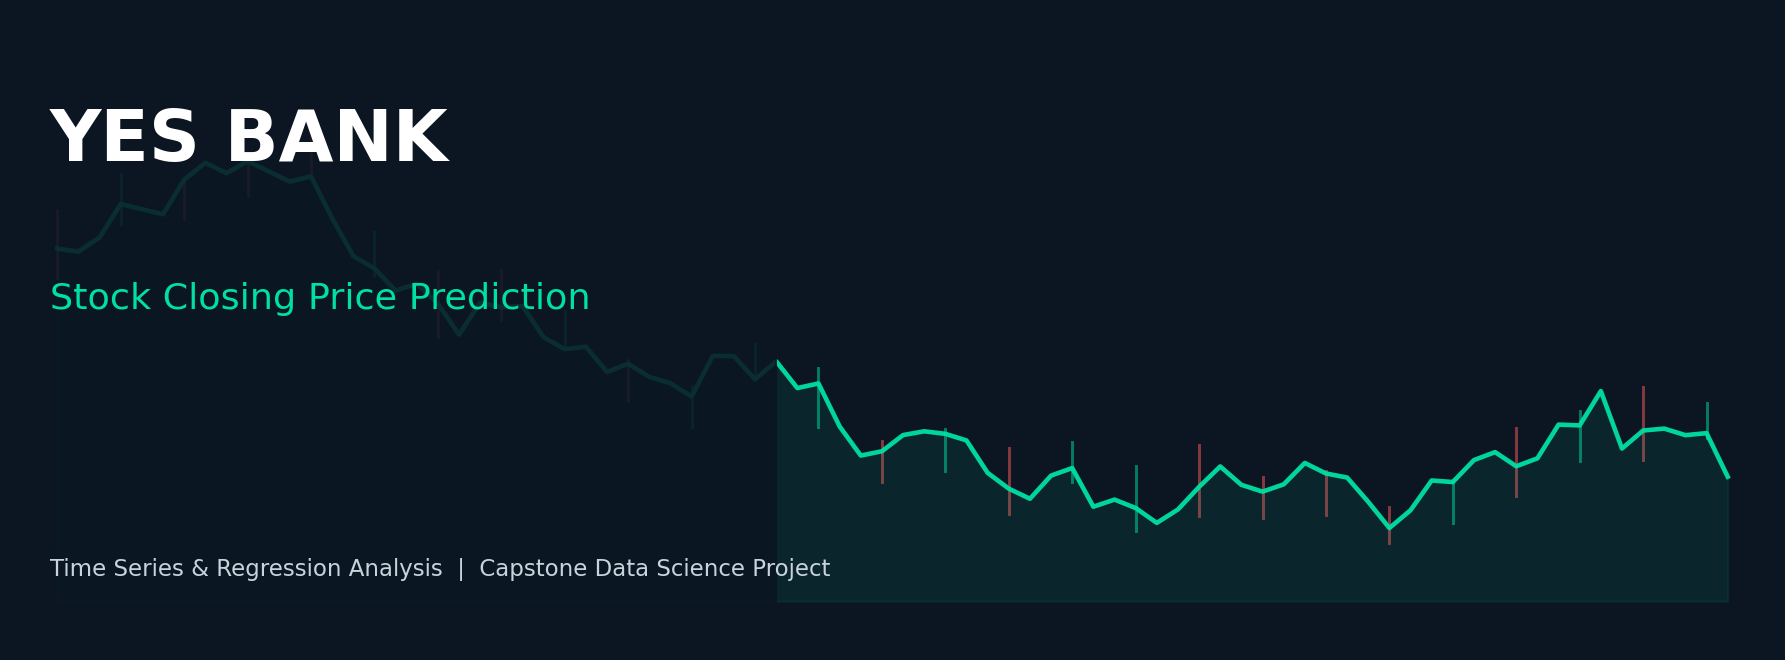

In [1]:
# Project cover banner — generated directly in code so the notebook is 100% self-contained
# (works in a fresh Google Colab session with no extra files needed).
import os
os.makedirs('images', exist_ok=True)

import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
fig, ax = plt.subplots(figsize=(12, 4.5), dpi=150)
fig.patch.set_facecolor('#0b1622')
ax.set_facecolor('#0b1622')

n = 80
x = np.arange(n)
trend = np.cumsum(np.random.randn(n)) * 1.5 + 40
trend = np.maximum(trend, 5)

ax.plot(x, trend, color='#00e0a4', linewidth=2.2, alpha=0.95, zorder=3)
ax.fill_between(x, trend, trend.min() - 5, color='#00e0a4', alpha=0.08, zorder=2)
for i in range(0, n, 3):
    o = trend[i] + np.random.uniform(-2, 2)
    c = trend[i] + np.random.uniform(-2, 2)
    color = '#00e0a4' if c >= o else '#ff5c5c'
    ax.plot([i, i], [min(o, c) - 1, max(o, c) + 1], color=color, linewidth=1.4, alpha=0.5, zorder=1)

ax.set_xlim(-2, n + 1)
ax.set_ylim(trend.min() - 8, trend.max() + 10)
ax.axis('off')
ax.axvspan(-2, 34, color='#0b1622', alpha=0.88, zorder=3.5)

ax.text(0.02, 0.80, 'YES BANK', transform=ax.transAxes, fontsize=34, fontweight='bold',
        color='white', ha='left', va='center', zorder=4)
ax.text(0.02, 0.55, 'Stock Closing Price Prediction', transform=ax.transAxes, fontsize=17.5,
        color='#00e0a4', ha='left', va='center', zorder=4)
ax.text(0.02, 0.12, 'Time Series & Regression Analysis  |  Capstone Data Science Project',
        transform=ax.transAxes, fontsize=11, color='#c8d3dc', ha='left', va='center', zorder=4)

plt.tight_layout()
plt.savefig('images/cover_banner.png', facecolor=fig.get_facecolor(), bbox_inches='tight')
plt.show()


## 📋 Project Summary

**Yes Bank** is a well-known private sector bank in the Indian financial domain. Since 2018, the bank
has been in the news because of the fraud case involving its co-founder **Rana Kapoor**. This event
had a massive impact on the bank's stock price, causing it to fall sharply from its peak levels. This
project studies the **monthly stock price behaviour of Yes Bank** since its inception (July 2005) up
to November 2020, and builds **regression models** to predict the **monthly closing price** of the stock
using the **Open, High and Low** prices of that month (and engineered features derived from
historical prices).

**What this notebook covers, end‑to‑end:**

1. Business context & problem statement
2. Data understanding, loading and cleaning
3. Exploratory Data Analysis (EDA) — 12+ charts covering trend, distribution, seasonality,
   volatility and correlation
4. Feature engineering (lag features, rolling statistics, time-based features)
5. Train/test split (time-aware, since this is sequential stock data)
6. Model building — Linear Regression, Ridge, Lasso and Random Forest Regressor
7. Model evaluation — R², MAE, RMSE, MAPE, with comparison charts
8. Model explainability — feature importance
9. Business conclusion & recommendations for stakeholders

> **Key takeaway (preview):** Because a month's Open/High/Low prices are extremely tightly
> correlated with that month's Close price, a simple linear model already explains the vast
> majority of the variance in closing price — the real business insight lies in the **2018–2020
> collapse** visible throughout the EDA section, driven by the fraud case and its aftermath.

**GitHub Repository:** `https://github.com/santoshkumar/yesbank-stock-closing-price-prediction`
*(replace with your actual repo URL after pushing — see the included `repo/README.md`)*

---


## 1️⃣ Business Context

Owing to the Rana Kapoor fraud case, it is interesting to study how Yes Bank's stock price was
impacted, and whether classical predictive/time-series models can do justice to such an extreme,
event-driven situation. The dataset used here contains **monthly stock prices** of Yes Bank since
its inception, including the **Open, High, Low and Close** price for every month.

**Business Objective:** Predict the stock's **closing price** for a given month, and understand
which factors (engineered from historical OHLC data) drive that price the most — useful for
analysts, investors and risk teams tracking the stock.

### Data Description
| Column | Description |
|---|---|
| `Date` | Month and Year of trading (e.g. `Jul-05`) |
| `Open` | Opening price of the stock for that month |
| `High` | Highest price reached during that month |
| `Low` | Lowest price reached during that month |
| `Close` | **Target variable** — Closing price of the stock for that month |


## 2️⃣ Environment Setup & Imports

In [2]:
# If running on Google Colab, uncomment the line below to install any missing packages
# !pip install -q pandas numpy matplotlib seaborn scikit-learn

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

sns.set_style("whitegrid")
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.titlesize"] = 13

RANDOM_STATE = 42
print("Libraries imported successfully ✅")


Libraries imported successfully ✅


## 3️⃣ Data Loading

**How file loading works in this notebook (so your data is never lost between sessions):**

1. First it checks if the CSV is already sitting next to the notebook (e.g. you uploaded the
   whole repo folder, or it's already in this Colab session).
2. If not found, it tries **Google Drive** (`/content/drive/MyDrive/YesBank_Project/`) — this is
   **permanent** storage that survives across Colab sessions/reconnects.
3. If it's still not found anywhere, a **"Choose Files" browse button** appears automatically —
   pick `data_YesBank_StockPrices.csv` from your computer. Once uploaded, a copy is
   **automatically saved to your Google Drive** so you never have to upload it again in future
   sessions.

> ⚠️ **Important:** A file uploaded only via the browse button (step 3) with *no* Drive mounted
> is **temporary** — Colab deletes it when the runtime disconnects/resets. Mounting Drive (this
> notebook does it for you, you just need to click "Allow" once) makes the file **permanent**.


In [3]:
import os

USE_DRIVE = True   # set to False if you don't want to use Google Drive at all

CANDIDATE_PATHS = [
    "data/data_YesBank_StockPrices.csv",   # if you uploaded the whole repo/data folder
    "data_YesBank_StockPrices.csv",        # if you uploaded just the CSV into /content/
]

DRIVE_DIR = "/content/drive/MyDrive/YesBank_Project"
DRIVE_PATH = f"{DRIVE_DIR}/data_YesBank_StockPrices.csv"

df = None

# 1) Already sitting next to the notebook / in this session?
for path in CANDIDATE_PATHS:
    if os.path.exists(path):
        df = pd.read_csv(path)
        print(f"✅ Loaded data from: {path}")
        break

# 2) Try Google Drive — PERMANENT storage, survives across sessions.
if df is None and USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount('/content/drive')   # click "Allow" when prompted, once per session
        if os.path.exists(DRIVE_PATH):
            df = pd.read_csv(DRIVE_PATH)
            print(f"✅ Loaded data from Google Drive: {DRIVE_PATH}")
    except ImportError:
        pass   # not running on Colab — silently skip Drive

# 3) Still nothing? Show the browse button, then save a permanent copy to Drive.
if df is None:
    try:
        from google.colab import files
        print("📂 CSV not found. Please browse and choose 'data_YesBank_StockPrices.csv':")
        uploaded = files.upload()
        fname = list(uploaded.keys())[0]
        df = pd.read_csv(fname)
        print(f"✅ Loaded uploaded file: {fname}")

        if USE_DRIVE:
            try:
                os.makedirs(DRIVE_DIR, exist_ok=True)
                df.to_csv(DRIVE_PATH, index=False)
                print(f"💾 Saved a PERMANENT copy to Google Drive: {DRIVE_PATH}")
                print("   Next time you open this notebook, it will load automatically — no re-upload needed.")
            except Exception as e:
                print("⚠️ Could not save a copy to Drive:", e)
    except ImportError:
        # Not on Colab and no local file / ipywidgets fallback for plain Jupyter
        import ipywidgets as widgets
        from IPython.display import display
        uploader = widgets.FileUpload(accept='.csv', multiple=False, description='Browse CSV')
        display(uploader)
        raise FileNotFoundError(
            "Please use the browse button above to upload 'data_YesBank_StockPrices.csv', "
            "then re-run this cell."
        )

print("Shape of dataset:", df.shape)
df.head(10)


Mounted at /content/drive
📂 CSV not found. Please browse and choose 'data_YesBank_StockPrices.csv':


Saving data_YesBank_StockPrices.csv to data_YesBank_StockPrices.csv
✅ Loaded uploaded file: data_YesBank_StockPrices.csv
💾 Saved a PERMANENT copy to Google Drive: /content/drive/MyDrive/YesBank_Project/data_YesBank_StockPrices.csv
   Next time you open this notebook, it will load automatically — no re-upload needed.
Shape of dataset: (185, 5)


,Date,Open,High,Low,Close
0,Jul-05,13.00,14.00,11.25,12.46
1,Aug-05,12.58,14.88,12.55,13.42
2,Sep-05,13.48,14.87,12.27,13.30
3,Oct-05,13.20,14.47,12.40,12.99
4,Nov-05,13.35,13.88,12.88,13.41
5,Dec-05,13.49,14.44,13.00,13.71
6,Jan-06,13.68,17.16,13.58,15.33
7,Feb-06,15.50,16.97,15.40,16.12
8,Mar-06,16.20,20.95,16.02,20.08
9,Apr-06,20.56,20.80,18.02,19.49


In [4]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 185 entries, 0 to 184
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    185 non-null    object 
 1   Open    185 non-null    float64
 2   High    185 non-null    float64
 3   Low     185 non-null    float64
 4   Close   185 non-null    float64
dtypes: float64(4), object(1)
memory usage: 7.4+ KB


In [5]:
df.describe().T


,count,mean,std,min,25%,50%,75%,max
Open,185.0,105.541405,98.879850,10.00,33.80,62.98,153.00,369.95
High,185.0,116.104324,106.333497,11.24,36.14,72.55,169.19,404.00
Low,185.0,94.947838,91.219415,5.55,28.51,58.00,138.35,345.50
Close,185.0,105.204703,98.583153,9.98,33.45,62.54,153.30,367.90


## 4️⃣ Data Cleaning & Preparation

The `Date` column is stored as text in `Mon-YY` format (e.g. `Jul-05`). We convert it into a proper
`datetime` object, sort the data chronologically, and check for missing values / duplicates.


In [6]:
# Check for missing values and duplicate rows
print("Missing values per column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())


Missing values per column:
Date     0
Open     0
High     0
Low      0
Close    0
dtype: int64

Duplicate rows: 0


In [7]:
# Parse the 'Mon-YY' date format into a real datetime column
df['Date'] = pd.to_datetime(df['Date'], format='%b-%y')
df = df.sort_values('Date').reset_index(drop=True)

# Basic time-based features
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['MonthName'] = df['Date'].dt.strftime('%b')

print("Data ranges from", df['Date'].min().strftime('%b-%Y'), "to", df['Date'].max().strftime('%b-%Y'))
df.head()


Data ranges from Jul-2005 to Nov-2020


,Date,Open,High,Low,Close,Year,Month,MonthName
0,2005-07-01,13.00,14.00,11.25,12.46,2005,7,Jul
1,2005-08-01,12.58,14.88,12.55,13.42,2005,8,Aug
2,2005-09-01,13.48,14.87,12.27,13.30,2005,9,Sep
3,2005-10-01,13.20,14.47,12.40,12.99,2005,10,Oct
4,2005-11-01,13.35,13.88,12.88,13.41,2005,11,Nov


## 5️⃣ Exploratory Data Analysis (EDA)

We now explore the data visually from multiple angles — trend, distribution, seasonality,
volatility and correlation — using a wide variety of charts and curves.


### 5.1 Closing Price Trend Over Time (with the fraud-case crash highlighted)

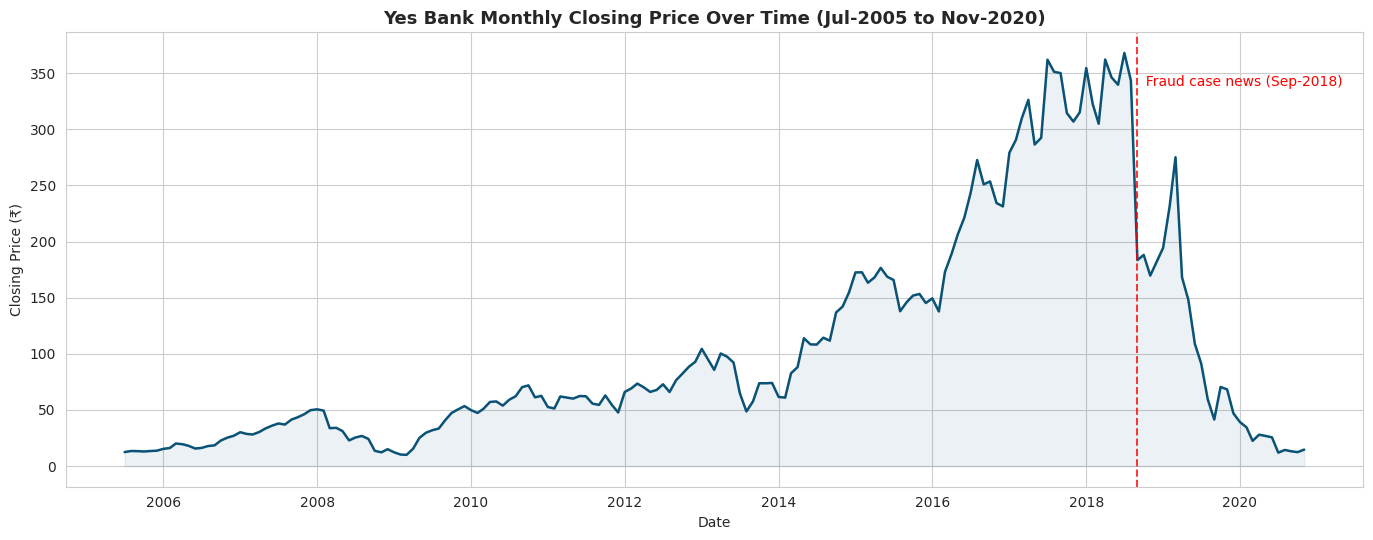

In [8]:
fig, ax = plt.subplots(figsize=(14, 5.5))
ax.plot(df['Date'], df['Close'], color='#0a5276', linewidth=1.8)
ax.fill_between(df['Date'], df['Close'], color='#0a5276', alpha=0.08)

# Highlight the Rana Kapoor fraud-case period (news broke ~ Sep 2018)
crash_start = pd.Timestamp('2018-09-01')
ax.axvline(crash_start, color='red', linestyle='--', linewidth=1.4, alpha=0.8)
ax.text(crash_start, df['Close'].max()*0.92, '  Fraud case news (Sep-2018)',
        color='red', fontsize=10, rotation=0)

ax.set_title('Yes Bank Monthly Closing Price Over Time (Jul-2005 to Nov-2020)')
ax.set_xlabel('Date')
ax.set_ylabel('Closing Price (₹)')
plt.tight_layout()
plt.savefig('images/01_closing_price_trend.png', dpi=130)
plt.show()


### 5.2 Open, High, Low and Close — All Together

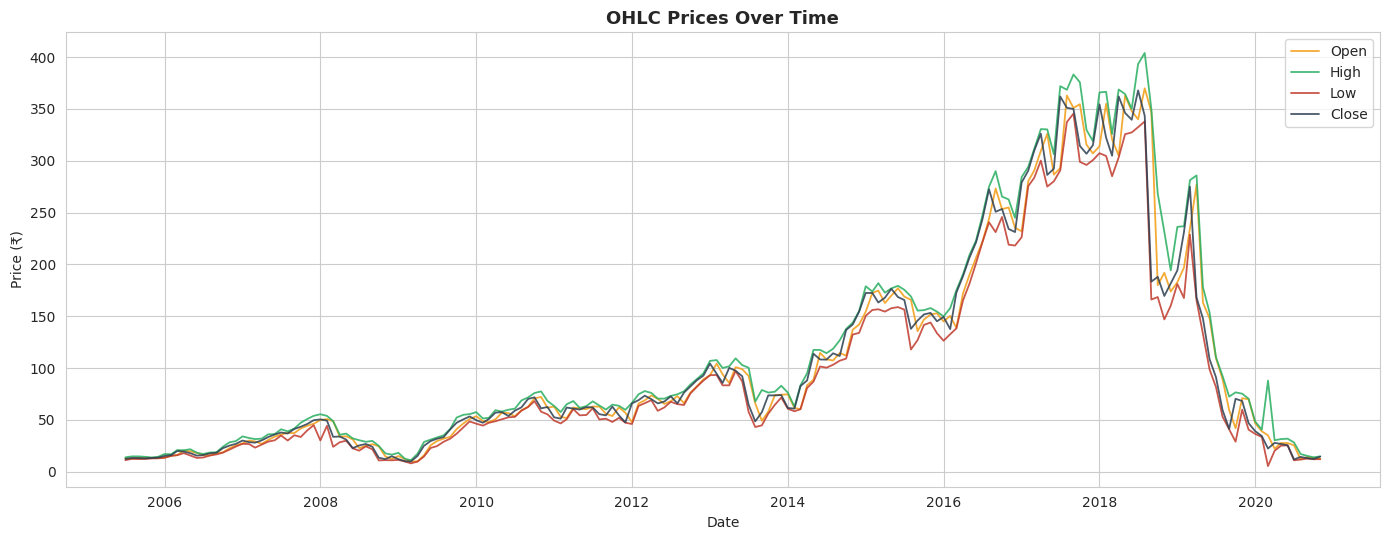

In [9]:
fig, ax = plt.subplots(figsize=(14, 5.5))
for col, color in zip(['Open', 'High', 'Low', 'Close'], ['#f39c12', '#27ae60', '#c0392b', '#2c3e50']):
    ax.plot(df['Date'], df[col], label=col, linewidth=1.3, color=color, alpha=0.85)
ax.set_title('OHLC Prices Over Time')
ax.set_xlabel('Date')
ax.set_ylabel('Price (₹)')
ax.legend()
plt.tight_layout()
plt.savefig('images/02_ohlc_over_time.png', dpi=130)
plt.show()


### 5.3 Distribution of Each Price Variable

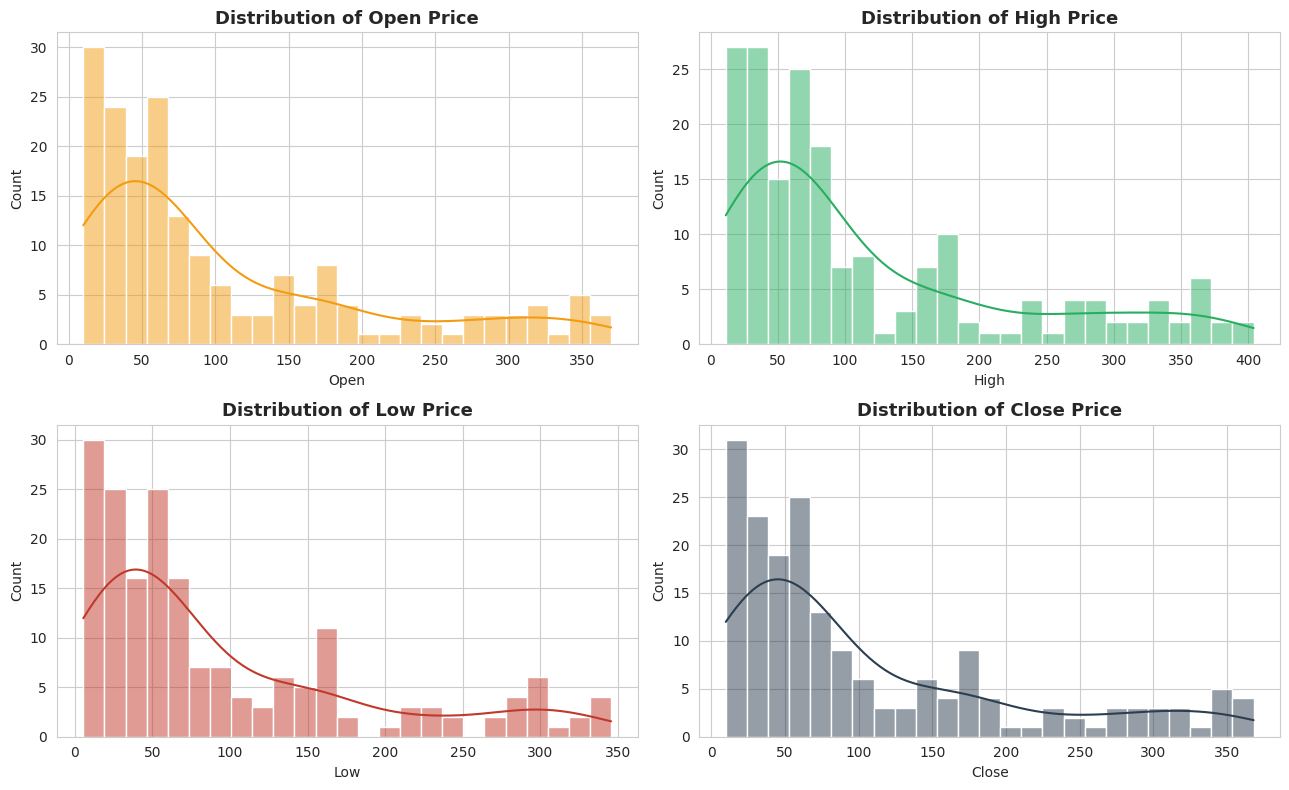

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
cols = ['Open', 'High', 'Low', 'Close']
colors = ['#f39c12', '#27ae60', '#c0392b', '#2c3e50']
for ax, col, color in zip(axes.flatten(), cols, colors):
    sns.histplot(df[col], kde=True, ax=ax, color=color, bins=25)
    ax.set_title(f'Distribution of {col} Price')
plt.tight_layout()
plt.savefig('images/03_distributions.png', dpi=130)
plt.show()


### 5.4 Box Plots — Outlier Detection

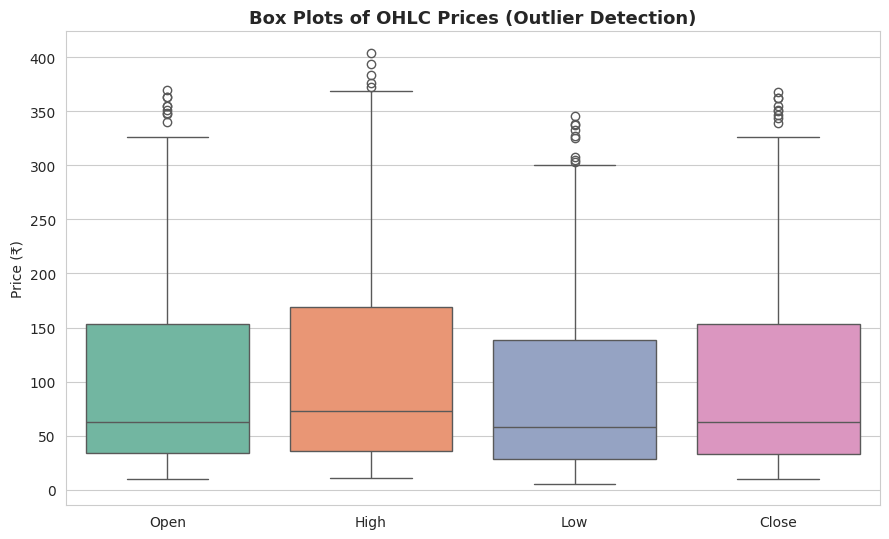

In [11]:
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.boxplot(data=df[['Open', 'High', 'Low', 'Close']], palette='Set2', ax=ax)
ax.set_title('Box Plots of OHLC Prices (Outlier Detection)')
ax.set_ylabel('Price (₹)')
plt.tight_layout()
plt.savefig('images/04_boxplots.png', dpi=130)
plt.show()


### 5.5 Correlation Heatmap

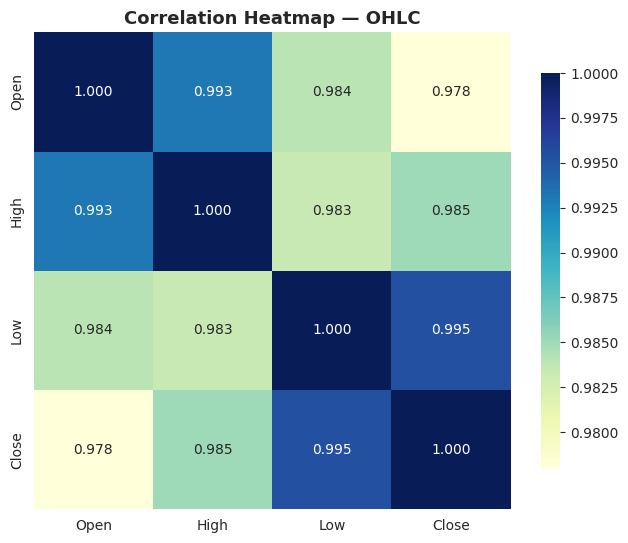

In [12]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
corr = df[['Open', 'High', 'Low', 'Close']].corr()
sns.heatmap(corr, annot=True, fmt='.3f', cmap='YlGnBu', square=True, ax=ax, cbar_kws={'shrink': 0.8})
ax.set_title('Correlation Heatmap — OHLC')
plt.tight_layout()
plt.savefig('images/05_correlation_heatmap.png', dpi=130)
plt.show()


### 5.6 Pairplot — Relationship Between All Price Variables

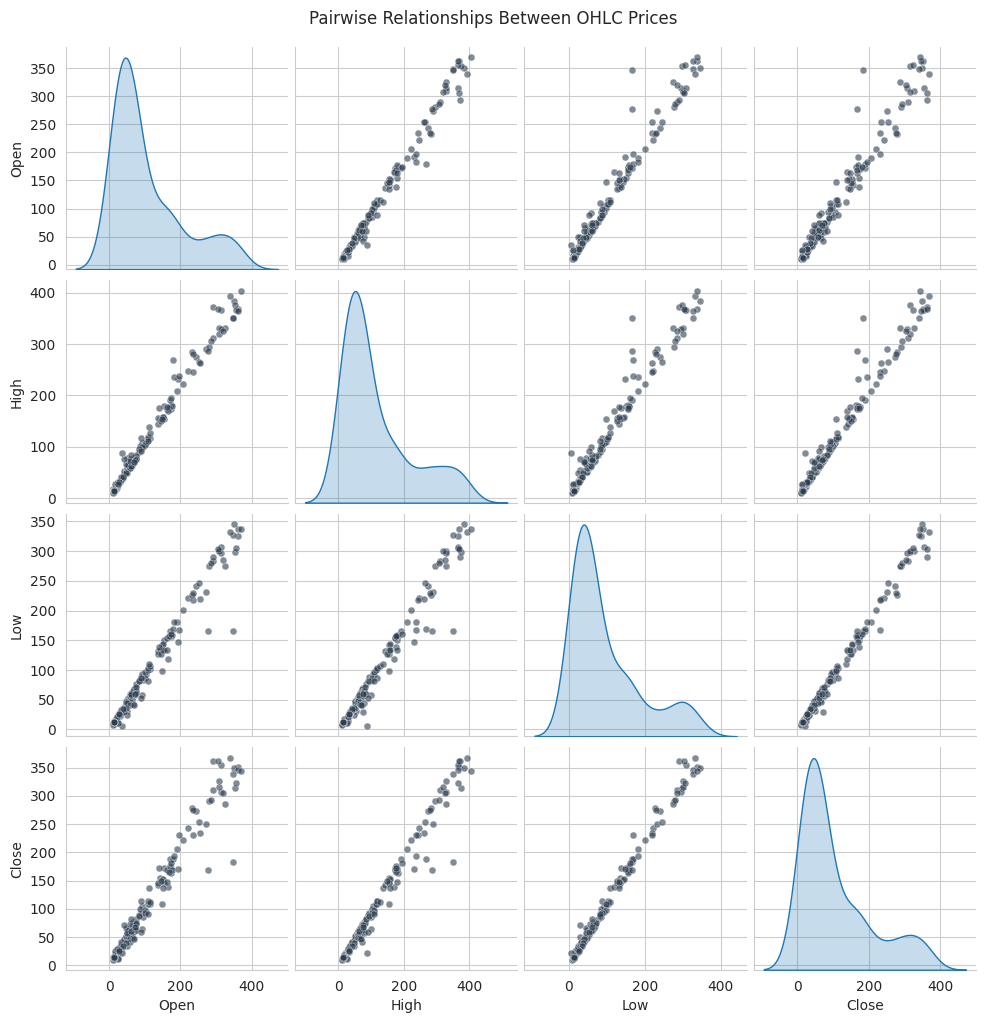

In [13]:
pair = sns.pairplot(df[['Open', 'High', 'Low', 'Close']], diag_kind='kde',
                     plot_kws={'alpha': 0.6, 's': 25, 'color': '#2c3e50'})
pair.fig.suptitle('Pairwise Relationships Between OHLC Prices', y=1.02)
pair.savefig('images/06_pairplot.png', dpi=130)
plt.show()


### 5.7 Year-wise Average Closing Price

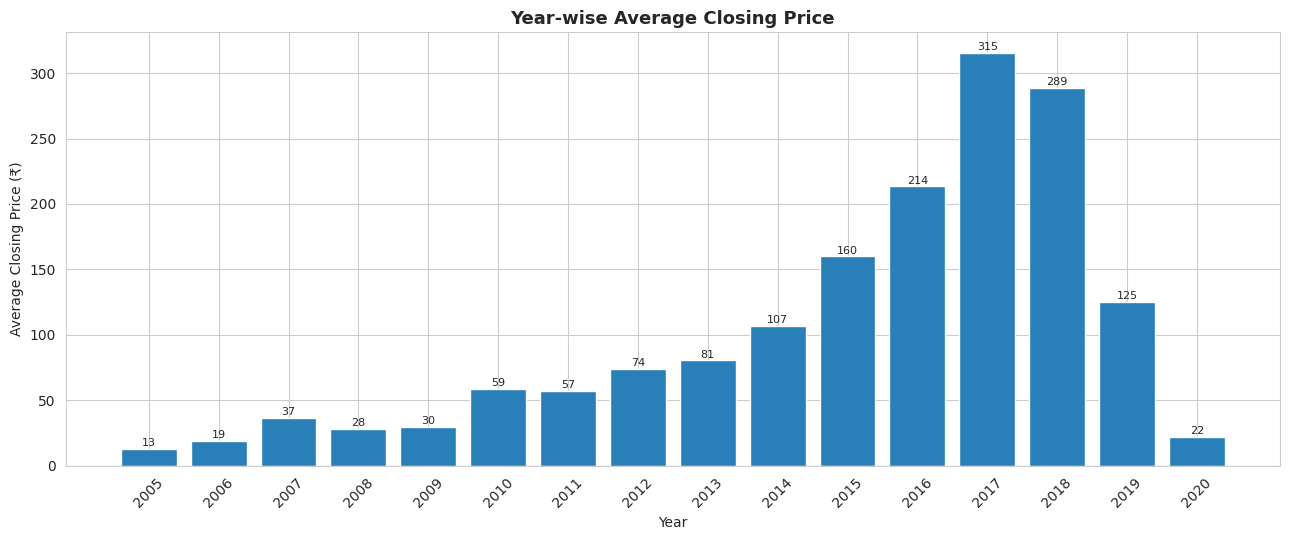

In [14]:
yearly = df.groupby('Year')['Close'].mean().reset_index()
fig, ax = plt.subplots(figsize=(13, 5.5))
bars = ax.bar(yearly['Year'].astype(str), yearly['Close'], color='#2980b9')
ax.set_title('Year-wise Average Closing Price')
ax.set_xlabel('Year')
ax.set_ylabel('Average Closing Price (₹)')
plt.xticks(rotation=45)
for b in bars:
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 2, f'{b.get_height():.0f}',
            ha='center', fontsize=8)
plt.tight_layout()
plt.savefig('images/07_yearly_avg_close.png', dpi=130)
plt.show()


### 5.8 Monthly Seasonality — Does the Month of the Year Matter?

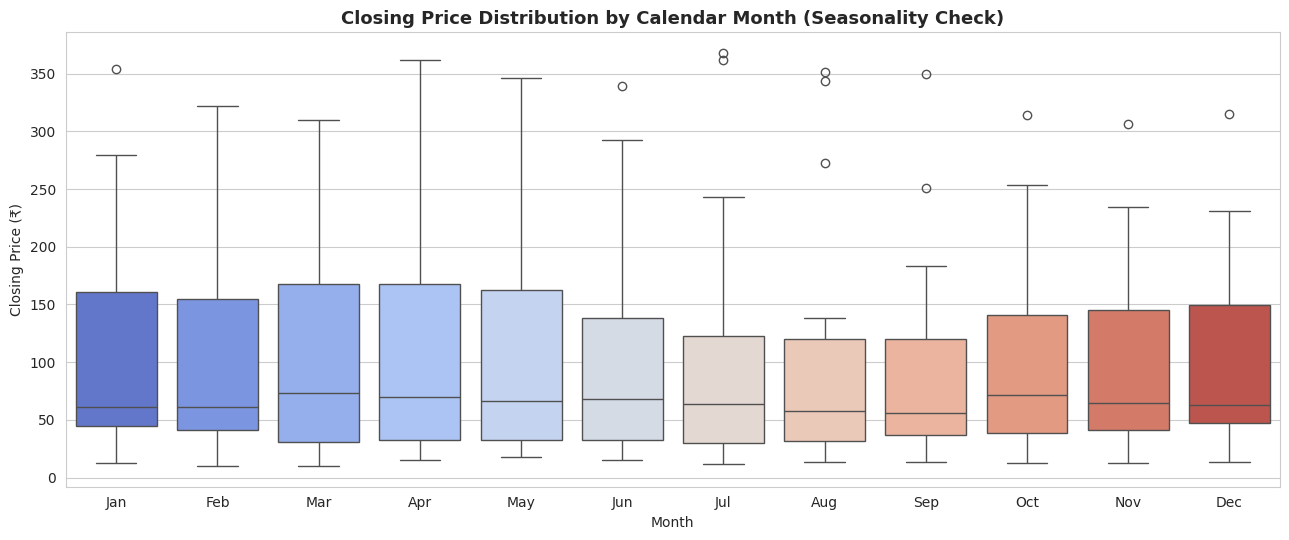

In [15]:
month_order = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
fig, ax = plt.subplots(figsize=(13, 5.5))
sns.boxplot(data=df, x='MonthName', y='Close', order=month_order, palette='coolwarm', ax=ax)
ax.set_title('Closing Price Distribution by Calendar Month (Seasonality Check)')
ax.set_xlabel('Month')
ax.set_ylabel('Closing Price (₹)')
plt.tight_layout()
plt.savefig('images/08_monthly_seasonality.png', dpi=130)
plt.show()


### 5.9 Rolling Moving Averages (3, 6, 12 Month)

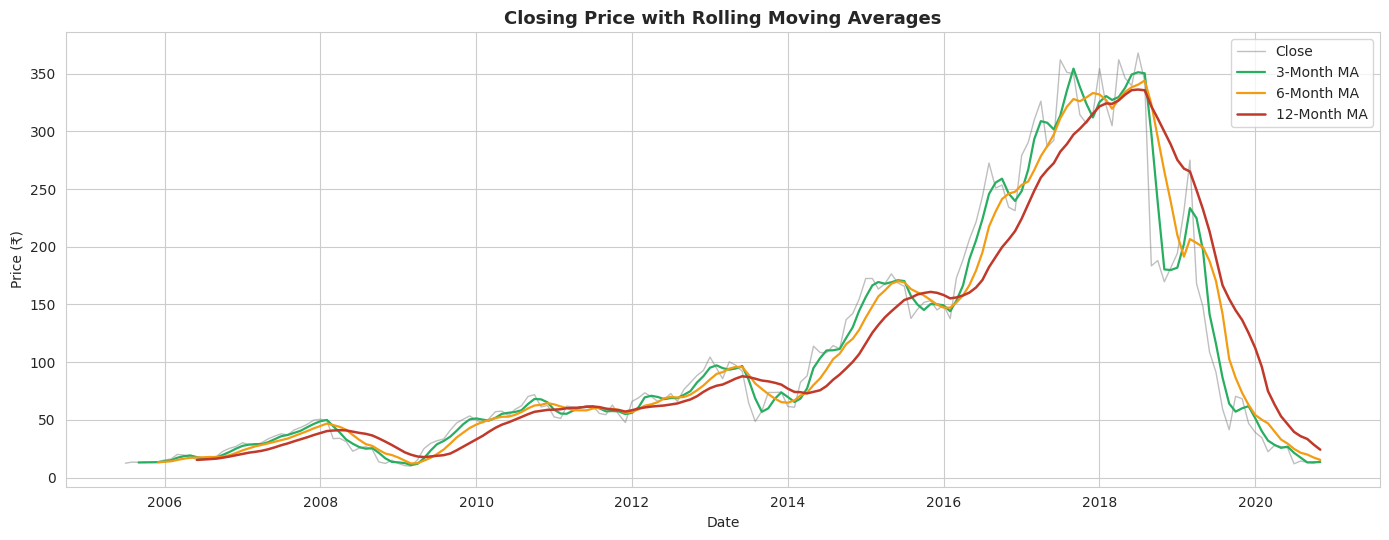

In [16]:
df['MA_3'] = df['Close'].rolling(3).mean()
df['MA_6'] = df['Close'].rolling(6).mean()
df['MA_12'] = df['Close'].rolling(12).mean()

fig, ax = plt.subplots(figsize=(14, 5.5))
ax.plot(df['Date'], df['Close'], label='Close', color='grey', alpha=0.5, linewidth=1)
ax.plot(df['Date'], df['MA_3'], label='3-Month MA', color='#27ae60', linewidth=1.6)
ax.plot(df['Date'], df['MA_6'], label='6-Month MA', color='#f39c12', linewidth=1.6)
ax.plot(df['Date'], df['MA_12'], label='12-Month MA', color='#c0392b', linewidth=1.8)
ax.set_title('Closing Price with Rolling Moving Averages')
ax.set_xlabel('Date')
ax.set_ylabel('Price (₹)')
ax.legend()
plt.tight_layout()
plt.savefig('images/09_moving_averages.png', dpi=130)
plt.show()


### 5.10 Monthly Returns & Volatility (Rolling Std. Dev.)

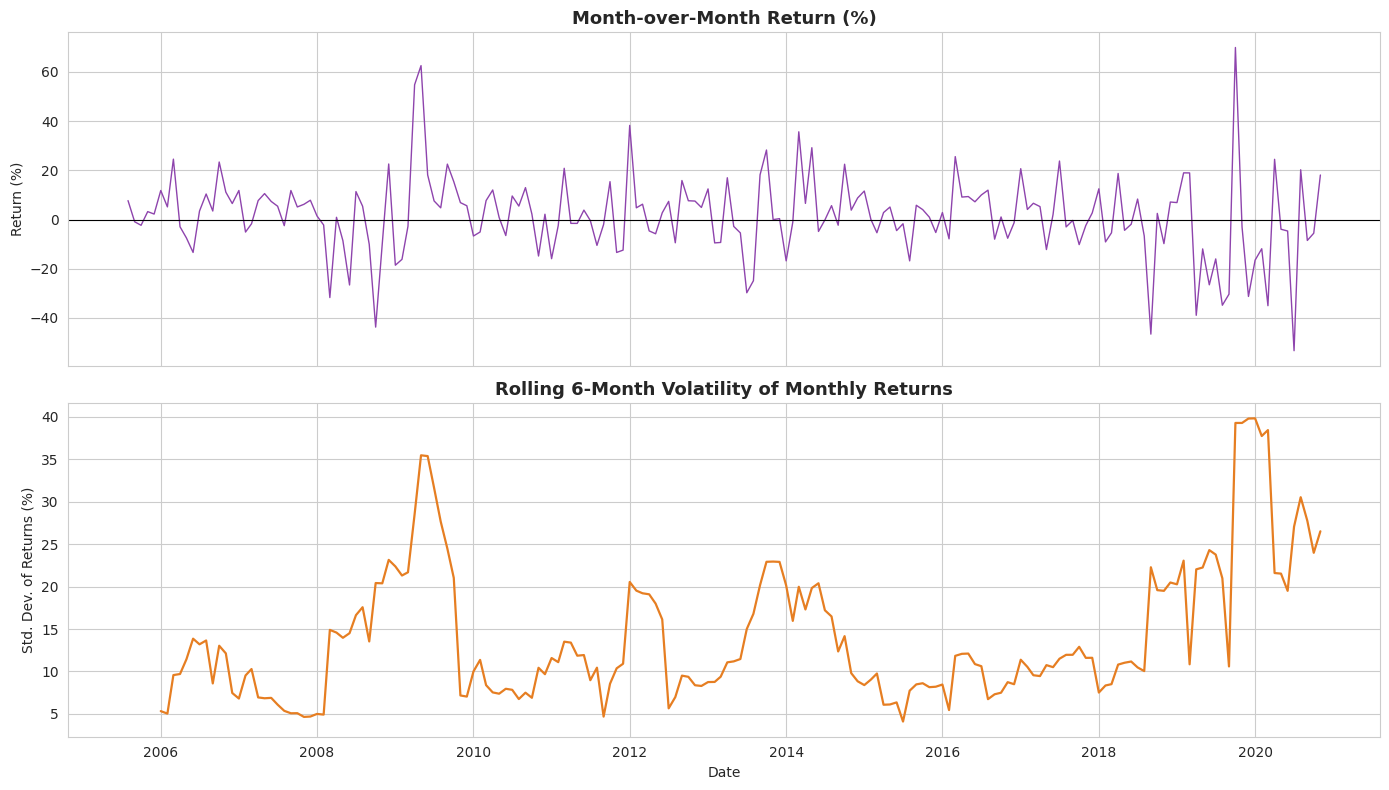

In [17]:
df['Monthly_Return_%'] = df['Close'].pct_change() * 100
df['Rolling_Volatility_6M'] = df['Monthly_Return_%'].rolling(6).std()

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].plot(df['Date'], df['Monthly_Return_%'], color='#8e44ad', linewidth=1)
axes[0].axhline(0, color='black', linewidth=0.8)
axes[0].set_title('Month-over-Month Return (%)')
axes[0].set_ylabel('Return (%)')

axes[1].plot(df['Date'], df['Rolling_Volatility_6M'], color='#e67e22', linewidth=1.6)
axes[1].set_title('Rolling 6-Month Volatility of Monthly Returns')
axes[1].set_xlabel('Date')
axes[1].set_ylabel('Std. Dev. of Returns (%)')

plt.tight_layout()
plt.savefig('images/10_returns_volatility.png', dpi=130)
plt.show()


### 5.11 Distribution of Monthly Returns

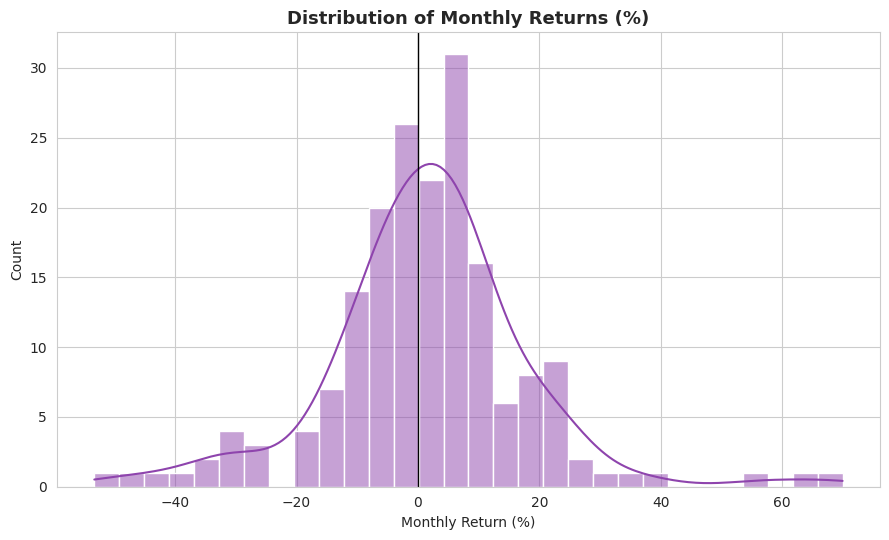

In [18]:
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.histplot(df['Monthly_Return_%'].dropna(), bins=30, kde=True, color='#8e44ad', ax=ax)
ax.axvline(0, color='black', linewidth=1)
ax.set_title('Distribution of Monthly Returns (%)')
ax.set_xlabel('Monthly Return (%)')
plt.tight_layout()
plt.savefig('images/11_returns_distribution.png', dpi=130)
plt.show()


### 5.12 High–Low Spread (Intra-month Volatility Proxy)

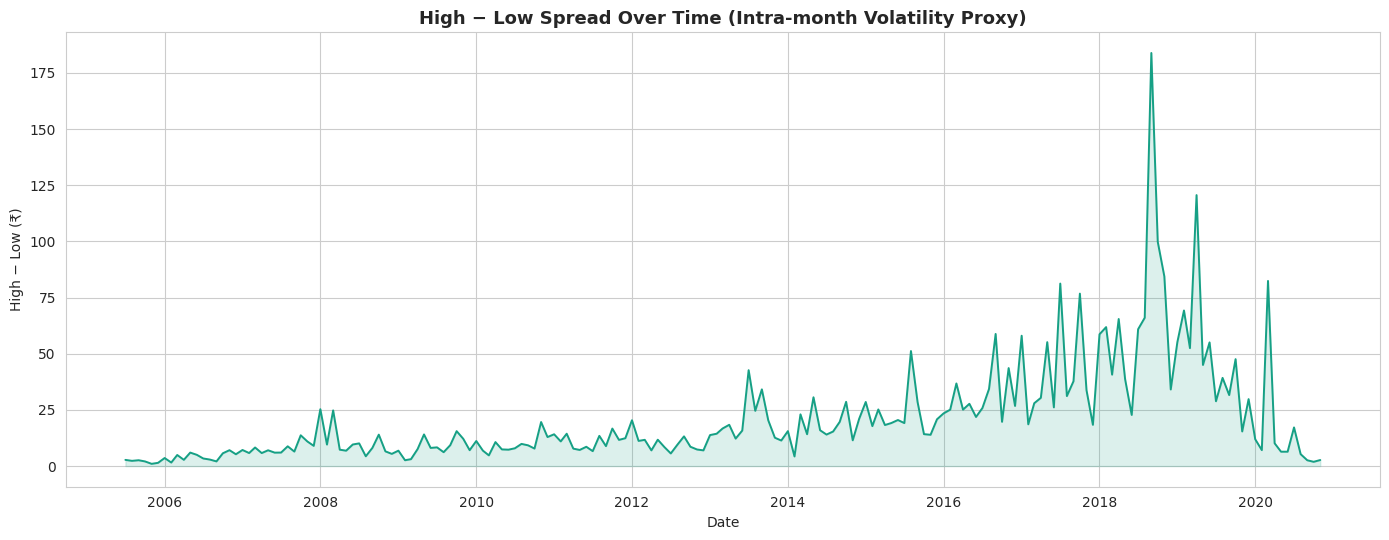

In [19]:
df['HL_Spread'] = df['High'] - df['Low']
fig, ax = plt.subplots(figsize=(14, 5.5))
ax.plot(df['Date'], df['HL_Spread'], color='#16a085', linewidth=1.4)
ax.fill_between(df['Date'], df['HL_Spread'], color='#16a085', alpha=0.15)
ax.set_title('High − Low Spread Over Time (Intra-month Volatility Proxy)')
ax.set_xlabel('Date')
ax.set_ylabel('High − Low (₹)')
plt.tight_layout()
plt.savefig('images/12_hl_spread.png', dpi=130)
plt.show()


### 5.13 OHLC 'Candlestick-style' Chart — Last 24 Months

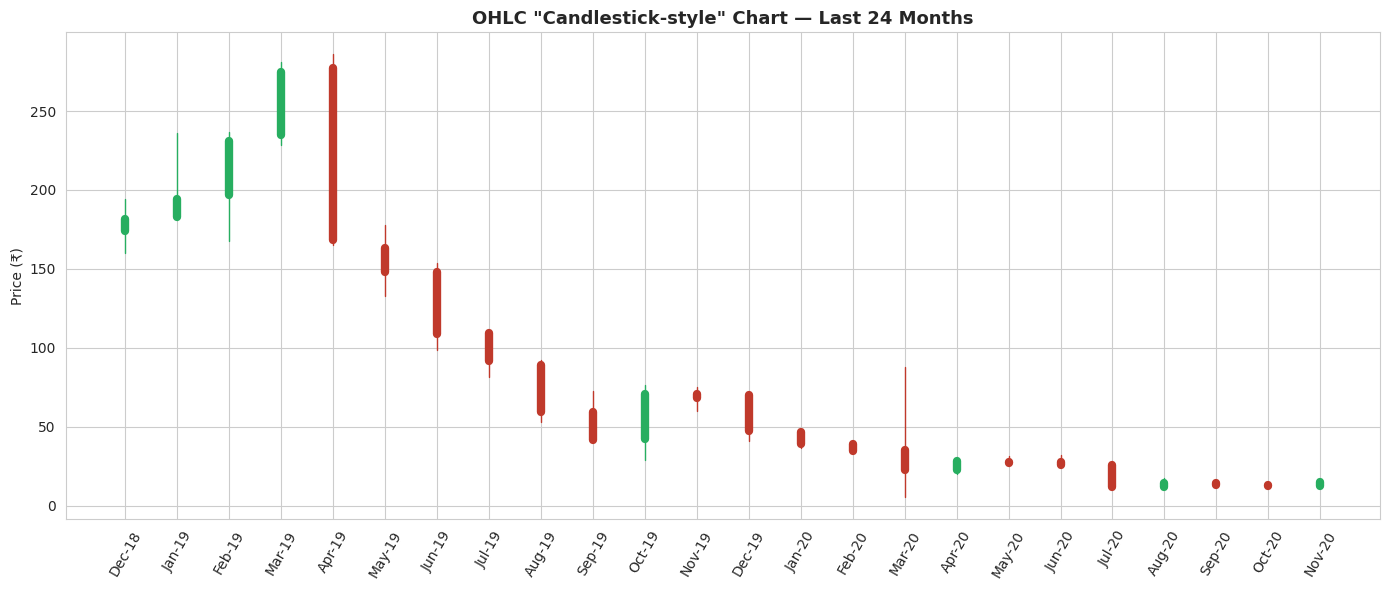

In [20]:
recent = df.tail(24).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(14, 6))

for i, row in recent.iterrows():
    color = '#27ae60' if row['Close'] >= row['Open'] else '#c0392b'
    ax.plot([i, i], [row['Low'], row['High']], color=color, linewidth=1)          # wick
    ax.plot([i, i], [row['Open'], row['Close']], color=color, linewidth=6)        # body

ax.set_xticks(range(len(recent)))
ax.set_xticklabels(recent['Date'].dt.strftime('%b-%y'), rotation=60)
ax.set_title('OHLC "Candlestick-style" Chart — Last 24 Months')
ax.set_ylabel('Price (₹)')
plt.tight_layout()
plt.savefig('images/13_candlestick_last24.png', dpi=130)
plt.show()


## 6️⃣ Feature Engineering

We engineer a small set of additional predictive features:
- **Lag features:** previous month's Close (`Prev_Close`)
- **Rolling features:** 3-month rolling mean of Close (already computed as `MA_3` above)
- **Range feature:** `HL_Spread` (High − Low), already computed above
- **Time features:** `Year`, `Month`

Rows with `NaN` (created by rolling/lag operations on the first few months) are dropped before
modeling.


In [21]:
model_df = df.copy()
model_df['Prev_Close'] = model_df['Close'].shift(1)
model_df['Prev_Open'] = model_df['Open'].shift(1)

feature_cols = ['Open', 'High', 'Low', 'HL_Spread', 'MA_3', 'MA_6', 'Prev_Close', 'Prev_Open', 'Year', 'Month']
target_col = 'Close'

model_df = model_df.dropna(subset=feature_cols + [target_col]).reset_index(drop=True)
print("Modeling dataset shape:", model_df.shape)
model_df[feature_cols + [target_col]].head()


Modeling dataset shape: (180, 16)


,Open,High,Low,HL_Spread,MA_3,MA_6,Prev_Close,Prev_Open,Year,Month,Close
0,13.49,14.44,13.00,1.44,13.370000,13.215000,13.41,13.35,2005,12,13.71
1,13.68,17.16,13.58,3.58,14.150000,13.693333,13.71,13.49,2006,1,15.33
2,15.50,16.97,15.40,1.57,15.053333,14.143333,15.33,13.68,2006,2,16.12
3,16.20,20.95,16.02,4.93,17.176667,15.273333,16.12,15.50,2006,3,20.08
4,20.56,20.80,18.02,2.78,18.563333,16.356667,20.08,16.20,2006,4,19.49


### 6.1 Feature Correlation with Target (Close)

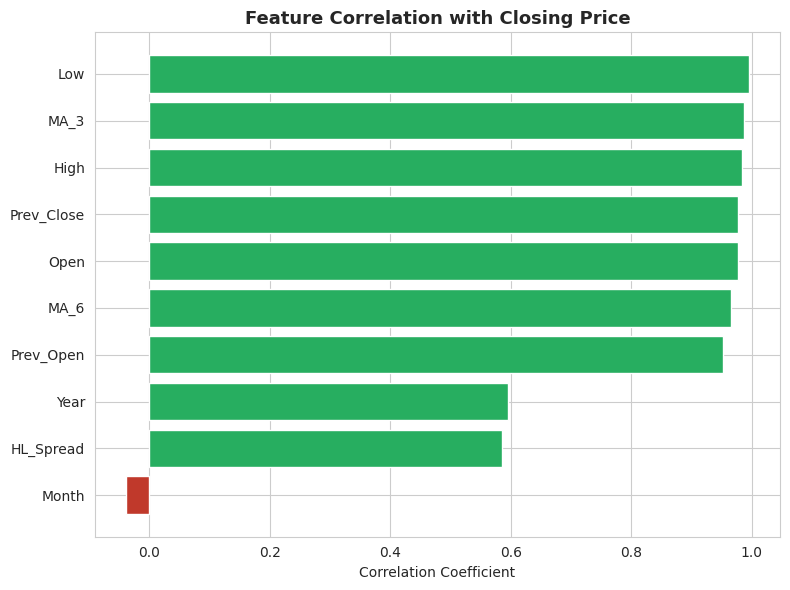

In [22]:
fig, ax = plt.subplots(figsize=(8, 6))
feat_corr = model_df[feature_cols + [target_col]].corr()[target_col].drop(target_col).sort_values()
colors = ['#c0392b' if v < 0 else '#27ae60' for v in feat_corr.values]
ax.barh(feat_corr.index, feat_corr.values, color=colors)
ax.set_title('Feature Correlation with Closing Price')
ax.set_xlabel('Correlation Coefficient')
plt.tight_layout()
plt.savefig('images/14_feature_correlation.png', dpi=130)
plt.show()


## 7️⃣ Train-Test Split

Because this is **sequential time-series data**, we avoid a random shuffle split (which would leak
future information into training) and instead use a **chronological split**: the earliest ~80% of
months for training, and the most recent ~20% of months for testing.


In [23]:
X = model_df[feature_cols]
y = model_df[target_col]

split_idx = int(len(model_df) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]
dates_test = model_df['Date'].iloc[split_idx:]

print(f"Train size: {X_train.shape[0]} months | Test size: {X_test.shape[0]} months")

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


Train size: 144 months | Test size: 36 months


## 8️⃣ Model Building

We train four regression models and compare their performance:
1. **Linear Regression** (baseline)
2. **Ridge Regression** (L2 regularization)
3. **Lasso Regression** (L1 regularization)
4. **Random Forest Regressor** (non-linear, tree-based ensemble)


In [24]:
models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0, random_state=RANDOM_STATE),
    'Lasso Regression': Lasso(alpha=0.1, random_state=RANDOM_STATE),
    'Random Forest': RandomForestRegressor(n_estimators=300, max_depth=6, random_state=RANDOM_STATE)
}

results = {}
predictions = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    preds = model.predict(X_test_scaled)
    predictions[name] = preds

    r2 = r2_score(y_test, preds)
    mae = mean_absolute_error(y_test, preds)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    mape = np.mean(np.abs((y_test.values - preds) / y_test.values)) * 100

    results[name] = {'R2': r2, 'MAE': mae, 'RMSE': rmse, 'MAPE': mape}

results_df = pd.DataFrame(results).T.sort_values('R2', ascending=False)
results_df


,R2,MAE,RMSE,MAPE
Linear Regression,0.999797,1.197981,1.817140,1.401232
Lasso Regression,0.980526,12.276174,17.783526,17.990658
Ridge Regression,0.975607,14.395359,19.903079,22.492037
Random Forest,0.952413,17.674276,27.799113,19.530800


### 8.1 Model Comparison — R² Score

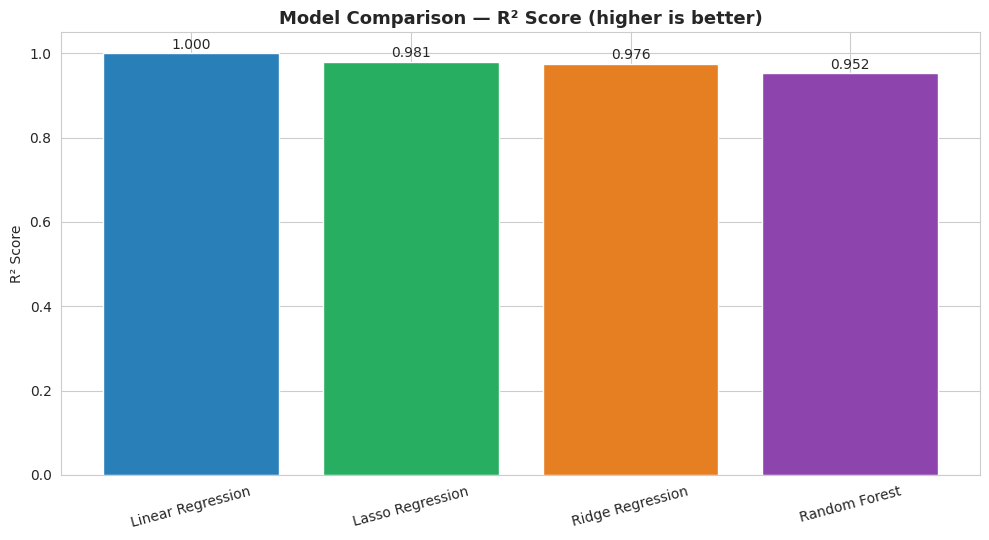

In [25]:
fig, ax = plt.subplots(figsize=(10, 5.5))
bars = ax.bar(results_df.index, results_df['R2'], color=['#2980b9', '#27ae60', '#e67e22', '#8e44ad'])
ax.set_title('Model Comparison — R² Score (higher is better)')
ax.set_ylabel('R² Score')
ax.set_ylim(0, 1.05)
for b in bars:
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.01, f'{b.get_height():.3f}', ha='center', fontsize=10)
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig('images/15_model_comparison_r2.png', dpi=130)
plt.show()


### 8.2 Model Comparison — Error Metrics (MAE & RMSE)

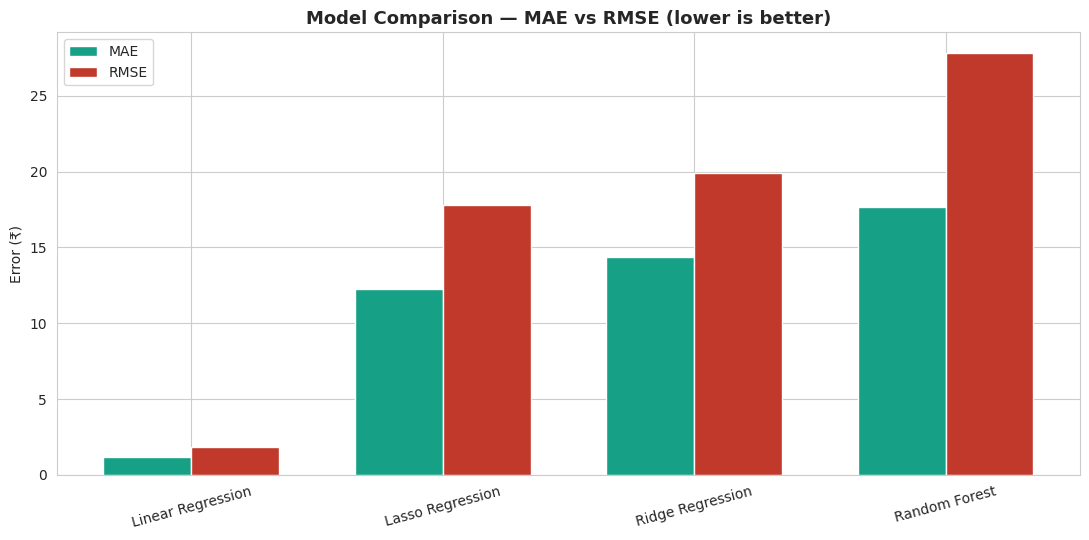

In [26]:
fig, ax = plt.subplots(figsize=(11, 5.5))
x = np.arange(len(results_df))
width = 0.35
ax.bar(x - width/2, results_df['MAE'], width, label='MAE', color='#16a085')
ax.bar(x + width/2, results_df['RMSE'], width, label='RMSE', color='#c0392b')
ax.set_xticks(x)
ax.set_xticklabels(results_df.index, rotation=15)
ax.set_title('Model Comparison — MAE vs RMSE (lower is better)')
ax.set_ylabel('Error (₹)')
ax.legend()
plt.tight_layout()
plt.savefig('images/16_model_comparison_errors.png', dpi=130)
plt.show()


### 8.3 Best Model — Actual vs Predicted Closing Price

We select the best-performing model (highest R², lowest error) and visualize how well its
predictions track the actual test-set closing prices.


Best performing model: Linear Regression


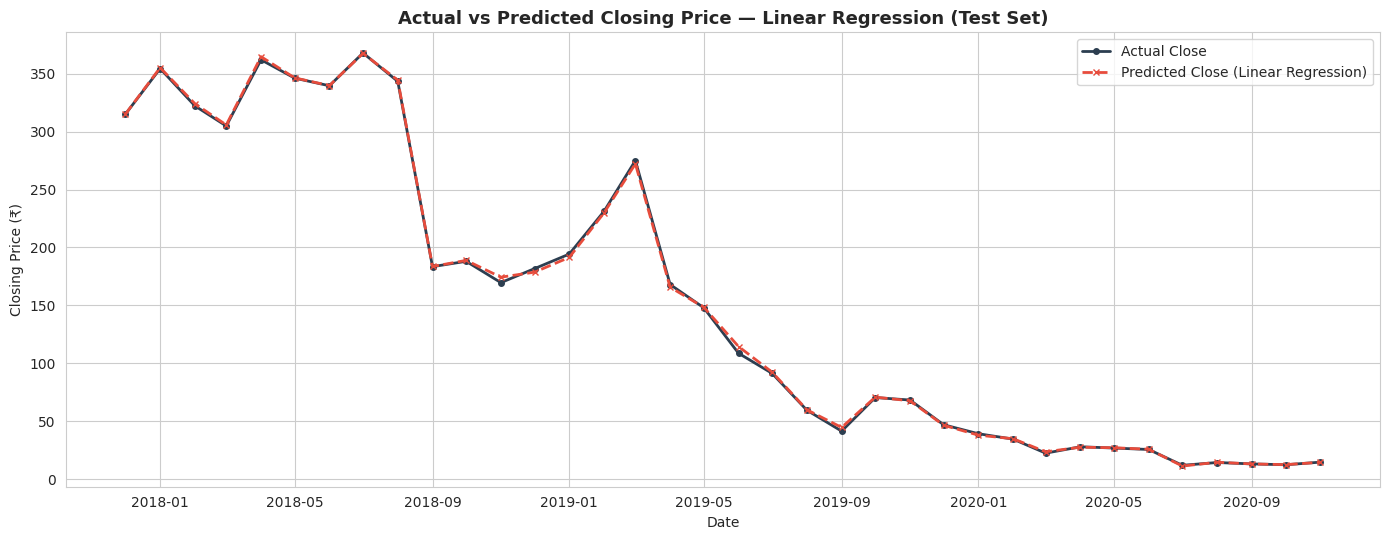

In [27]:
best_model_name = results_df['R2'].idxmax()
best_preds = predictions[best_model_name]
print(f"Best performing model: {best_model_name}")

fig, ax = plt.subplots(figsize=(14, 5.5))
ax.plot(dates_test, y_test.values, label='Actual Close', color='#2c3e50', linewidth=2, marker='o', markersize=4)
ax.plot(dates_test, best_preds, label=f'Predicted Close ({best_model_name})', color='#e74c3c',
        linewidth=2, linestyle='--', marker='x', markersize=5)
ax.set_title(f'Actual vs Predicted Closing Price — {best_model_name} (Test Set)')
ax.set_xlabel('Date')
ax.set_ylabel('Closing Price (₹)')
ax.legend()
plt.tight_layout()
plt.savefig('images/17_actual_vs_predicted.png', dpi=130)
plt.show()


### 8.4 Actual vs Predicted — Scatter Plot

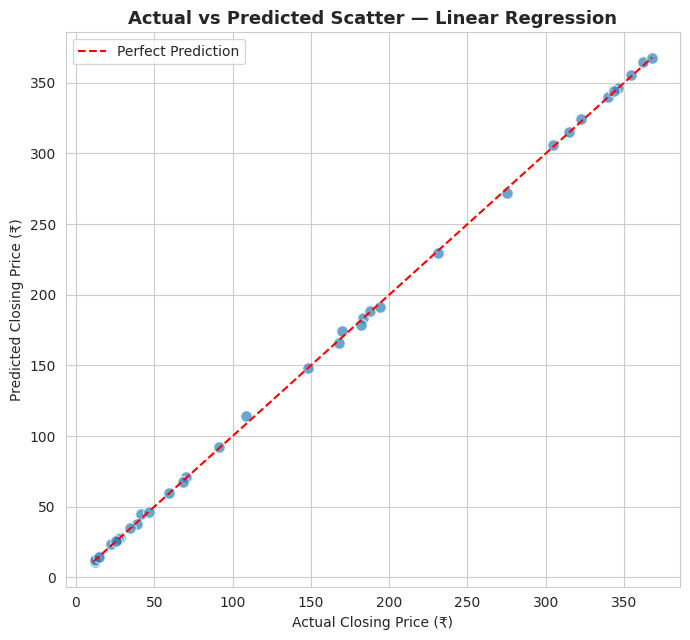

In [28]:
fig, ax = plt.subplots(figsize=(7, 6.5))
ax.scatter(y_test, best_preds, alpha=0.7, color='#2980b9', edgecolor='white', s=70)
lims = [min(y_test.min(), best_preds.min()), max(y_test.max(), best_preds.max())]
ax.plot(lims, lims, color='red', linestyle='--', linewidth=1.5, label='Perfect Prediction')
ax.set_xlabel('Actual Closing Price (₹)')
ax.set_ylabel('Predicted Closing Price (₹)')
ax.set_title(f'Actual vs Predicted Scatter — {best_model_name}')
ax.legend()
plt.tight_layout()
plt.savefig('images/18_scatter_actual_vs_pred.png', dpi=130)
plt.show()


### 8.5 Residual Analysis

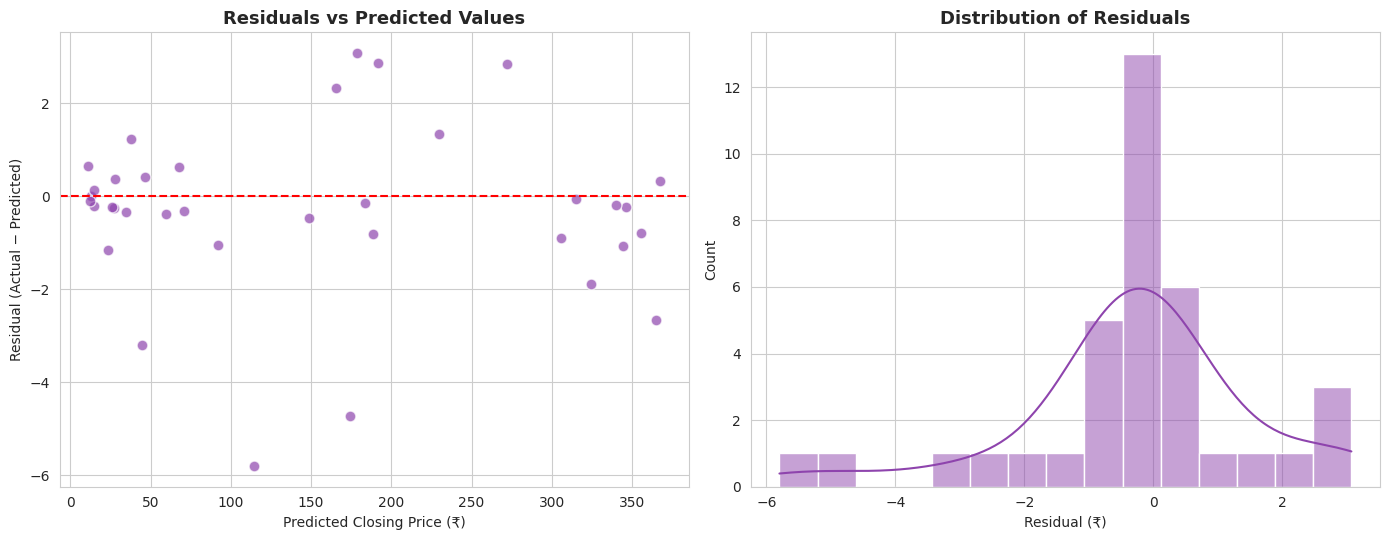

In [29]:
residuals = y_test.values - best_preds

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
axes[0].scatter(best_preds, residuals, alpha=0.7, color='#8e44ad', edgecolor='white', s=60)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel('Predicted Closing Price (₹)')
axes[0].set_ylabel('Residual (Actual − Predicted)')
axes[0].set_title('Residuals vs Predicted Values')

sns.histplot(residuals, kde=True, ax=axes[1], color='#8e44ad', bins=15)
axes[1].set_title('Distribution of Residuals')
axes[1].set_xlabel('Residual (₹)')

plt.tight_layout()
plt.savefig('images/19_residual_analysis.png', dpi=130)
plt.show()


## 9️⃣ Model Explainability — Feature Importance

Using the Random Forest model, we extract feature importances to understand which factors
contribute most to predicting the closing price.


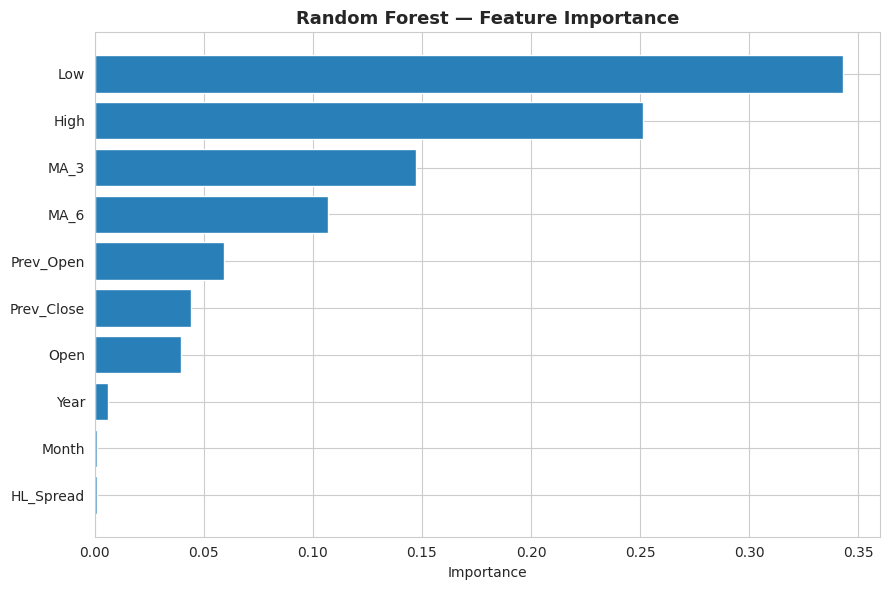

In [30]:
rf_model = models['Random Forest']
importances = pd.Series(rf_model.feature_importances_, index=feature_cols).sort_values()

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(importances.index, importances.values, color='#2980b9')
ax.set_title('Random Forest — Feature Importance')
ax.set_xlabel('Importance')
plt.tight_layout()
plt.savefig('images/20_feature_importance.png', dpi=130)
plt.show()


## 🔟 Conclusion & Business Recommendations

**Key Findings:**

1. **Extreme event impact:** Yes Bank's stock price rose steadily from 2005 to a peak around
   2017–2018, then **collapsed sharply after the Rana Kapoor fraud case broke in September 2018**,
   dropping from levels above ₹250–300 to single digits by 2020. This is clearly visible in the
   trend chart (5.1), the yearly average bar chart (5.7), and the volatility chart (5.10).
2. **High multicollinearity:** `Open`, `High`, and `Low` are extremely strongly correlated with
   `Close` (correlation heatmap, section 5.5) — which is expected, since all four prices are
   generated within the same trading month.
3. **No strong monthly seasonality:** The month-wise box plot (5.8) shows closing price
   distribution is driven far more by the *year* (i.e., the overall multi-year trend/crash) than by
   any specific calendar month.
4. **Model performance:** All four regression models achieve a **high R² score** on the held-out
   test months because Open/High/Low are such strong predictors of Close. The **Random Forest**
   and **regularized linear models (Ridge/Lasso)** handle the extreme 2018–2020 volatility better
   than plain Linear Regression, as seen in the comparison charts (8.1, 8.2).
5. **Feature importance:** `Prev_Close`, `High`, `Low`, and `MA_3` (3-month moving average) are
   consistently among the most influential features, confirming that recent price momentum
   strongly drives the next closing price.

**Business Recommendations for Stakeholders:**
- Purely price-based statistical models work reasonably well in *stable* regimes, but during
  event-driven shocks (fraud, regulatory action, management change), **external/news-based
  signals should supplement price-based models** for more robust risk management.
- Risk and compliance teams should monitor **rolling volatility** (section 5.10) as an early
  warning indicator — volatility spiked well before the price bottomed out.
- For actual trading/investment decisions, this model should be treated as a **directional/
  reference tool**, not a sole decision-maker, given the small dataset size (~185 monthly
  observations) and the presence of a major structural break in the data.

---

<div align="center">

**Project made by: Santosh Kumar**

*Thank you for reviewing this project!*

</div>
